# Stage 11: Network Resilience
**Project:** Hospital Care Quality & Efficiency Analytics
**Data:** the validated mart (episodes, facilities, daily census, network bed capacity)

**Question:** how are the network's facilities connected, and what happens to bed capacity and to the
other facilities if the most connected one goes down?

**Approach**
* **Nodes** are facilities with inpatient episodes in 2017 to 2025. Two facilities are **linked** when the same
  patients were treated at both; the more patients they share, the stronger the link.
* **Outage scenario (2023 to 2025):** the cardiac center closes for the whole test period.
    * The network loses the cardiac center's share of the 90-bed pool (its share of the average nightly census).
    * Each of its patients moves to the other facility they already used. Patients who used no other facility
      are spread across the cardiac center's existing links, in proportion to the patients each link shares.
* **Impact** is measured against primary goal 2 from the counterfactuals (no day above 92% occupancy, 85% as the
  safe level), with and without the recommended bed pathways (20% of lung cancer stays as day cases).

**A note on the data.** Synthea assigns patients to facilities mainly by distance and sends every cardiac case to
one facility. The network's shape therefore reflects how the simulation works rather than real referral patterns,
so the results show what a single point of failure means, not a forecast for a real hospital system.

| Section | Question |
|---|---|
| 1 | Build the network |
| 2 | Which facilities matter most? |
| 3 | The network on a map |
| 4 | The outage scenario: inputs |
| 5 | Where do the cardiac center's patients go? |
| 6 | What happens to bed occupancy? |
| 7 | The load on the receiving facilities |
| 8 | Save the results |
| 9 | Summary |

## 0. Setup

In [22]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sqlalchemy import text

# Find the project root (the folder containing .env) and import config.py from python/
root = Path.cwd()
while not (root / ".env").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "python"))
from config import get_engine

engine = get_engine()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def q(sql):
    """Run a SQL query in PostgreSQL and return the (small) result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


settings = q("""
    -- query: settings
    SELECT w.test_start_date, w.end_date, w.safe_occupancy, w.max_occupancy, c.beds, c.avg_census_in_window
    FROM mart.analysis_window w CROSS JOIN mart.network_capacity c
""").iloc[0]
TEST_START, TEST_END = pd.Timestamp(settings["test_start_date"]), pd.Timestamp(settings["end_date"])
SAFE, MAX = float(settings["safe_occupancy"]), float(settings["max_occupancy"])
BEDS = int(settings["beds"])
print(f"Network beds: {BEDS}, test period {TEST_START:%Y-%m-%d} to {TEST_END:%Y-%m-%d}")

Network beds: 90, test period 2023-01-01 to 2025-12-31


## 1. Build the network
Facilities are linked by patients treated at both during 2017 to 2025.

In [23]:
nodes = q("""
    -- query: nodes
    SELECT organization_id, hospital_name, city, facility_type, episodes_in_window, latitude, longitude
    FROM mart.dim_hospital
    WHERE episodes_in_window > 0
""")

patient_facility = q("""
    -- query: patient_facility
    SELECT patient_id, organization_id, COUNT(*) AS episodes
    FROM mart.fact_episode
    GROUP BY patient_id, organization_id
""")

edges = (patient_facility[["patient_id", "organization_id"]]
         .merge(patient_facility[["patient_id", "organization_id"]], on="patient_id", suffixes=("_a", "_b")))
edges = edges[edges["organization_id_a"] < edges["organization_id_b"]]
edges = (edges.groupby(["organization_id_a", "organization_id_b"]).size()
              .reset_index(name="shared_patients")
              .rename(columns={"organization_id_a": "source", "organization_id_b": "target"}))

HUB = nodes.loc[nodes["facility_type"] == "Cardiac centre", "organization_id"]
assert len(HUB) == 1, "Expected exactly one cardiac center"
HUB = HUB.iloc[0]
HUB_NAME = nodes.loc[nodes["organization_id"] == HUB, "hospital_name"].iloc[0]

G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.organization_id, name=r.hospital_name, episodes=r.episodes_in_window)
for r in edges.itertuples():
    G.add_edge(r.source, r.target, weight=r.shared_patients)

multi = (patient_facility.groupby("patient_id").size() > 1).sum()
hub_links = sum(1 for _ in G.edges(HUB))
connected = [n for n in G.nodes if G.degree(n) > 0]
print(f"Facilities: {G.number_of_nodes()}, links: {G.number_of_edges()}, "
      f"facilities with at least one link: {len(connected)}")
print(f"Patients treated at more than one facility: {multi:,} of {patient_facility['patient_id'].nunique():,}")
print(f"Links involving {HUB_NAME} (the cardiac center): {hub_links} of {G.number_of_edges()}")
print(f"Links with 5 or more shared patients: {(edges['shared_patients'] >= 5).sum()}")

Facilities: 153, links: 138, facilities with at least one link: 139
Patients treated at more than one facility: 964 of 19,042
Links involving Fitchburg Outpatient Clinic (the cardiac center): 138 of 138
Links with 5 or more shared patients: 63


**Interpretation:** Of the 153 facilities with inpatient episodes, 139 share at least one patient with another facility, through 138 links. Only 964 of 19,042 patients (5%) were treated at more than one facility, and **every one of the 138 links runs through Fitchburg Outpatient Clinic**, the network's cardiac center. No two other facilities share a single patient. The network is a pure **star**: one hub with 138 spokes and no connections between the spokes. 63 of the links carry 5 or more shared patients; the rest are thin.

## 2. Which facilities matter most?
Three standard measures:
* **Links (degree):** how many other facilities share patients with this one
* **Shared patients (weighted degree):** the total patients shared across all its links
* **Betweenness:** how often a facility sits on the shortest path between two others; a high value marks a broker
  that holds the network together

A **cut point** (articulation point) is a facility whose removal splits the network into disconnected pieces.

In [24]:
centrality = pd.DataFrame({
    "organization_id": list(G.nodes),
    "links": [G.degree(n) for n in G.nodes],
    "shared_patients": [G.degree(n, weight="weight") for n in G.nodes],
})
betweenness = nx.betweenness_centrality(G, normalized=True)
centrality["betweenness"] = centrality["organization_id"].map(betweenness)
cut_points = set(nx.articulation_points(G))
centrality["is_cut_point"] = centrality["organization_id"].isin(cut_points)
centrality = centrality.merge(nodes[["organization_id", "hospital_name", "facility_type", "episodes_in_window"]],
                              on="organization_id")
centrality["is_hub"] = centrality["organization_id"] == HUB

components_with_hub = nx.number_connected_components(G.subgraph(connected))
G_out = G.copy(); G_out.remove_node(HUB)
components_without_hub = nx.number_connected_components(G_out.subgraph([n for n in connected if n != HUB]))
isolated_without_hub = sum(1 for n in G_out.nodes if G_out.degree(n) == 0 and G.degree(n) > 0)

print(f"Cut points: {len(cut_points)} ({', '.join(nodes.set_index('organization_id').loc[list(cut_points), 'hospital_name'])})")
print(f"Connected pieces among linked facilities: {components_with_hub} with the cardiac center, "
      f"{components_without_hub} without it")
print(f"Facilities left with no links if the cardiac center is removed: {isolated_without_hub}")
(centrality.sort_values("shared_patients", ascending=False)
           [["hospital_name", "facility_type", "episodes_in_window", "links", "shared_patients", "betweenness", "is_cut_point"]]
           .head(10).round(3))

Cut points: 1 (Fitchburg Outpatient Clinic)
Connected pieces among linked facilities: 1 with the cardiac center, 138 without it
Facilities left with no links if the cardiac center is removed: 138


,hospital_name,facility_type,episodes_in_window,links,shared_patients,betweenness,is_cut_point
0,Fitchburg Outpatient Clinic,Cardiac centre,7053,138,964,0.824,True
91,Cape Cod Hospital Inc,General,694,1,45,0.000,False
88,Tewksbury Hospital,General,821,1,30,0.000,False
136,Encompass Health Braintree Hospital Of Braintree,General,453,1,27,0.000,False
126,Milford Regional Medical Center,General,568,1,25,0.000,False
56,4499 Acushnet Avenue Operating Company LLC,General,407,1,23,0.000,False
142,Encompass Health Rehabilitation Hosp Of New En...,General,346,1,22,0.000,False
50,Dana Farber Cancer Institute,General,315,1,22,0.000,False
44,Vibra Hospital Of Western Massachusetts LLC,General,596,1,20,0.000,False
22,Boston Medical Center Corporation,General,538,1,18,0.000,False


**Interpretation:** The cardiac center dominates every measure. It has 138 links (every other connected facility has exactly 1), it carries all 964 shared patients, and it is the only facility with any betweenness (0.82), because every path between two other facilities passes through it. It is the network's **only cut point**: removing it leaves the 138 facilities it connects with no links at all, splitting one connected network into 138 isolated pieces. The strongest spokes lead to large general hospitals such as Cape Cod Hospital (45 shared patients), Tewksbury Hospital (30) and Milford Regional Medical Center (25). In network terms, the cardiac center is a **single point of failure**: the other facilities depend on it for cardiac care but not on each other.

## 3. The network on a map
Each dot is a facility, sized by its episodes in 2017 to 2025; each line is a link, thicker for more shared patients.

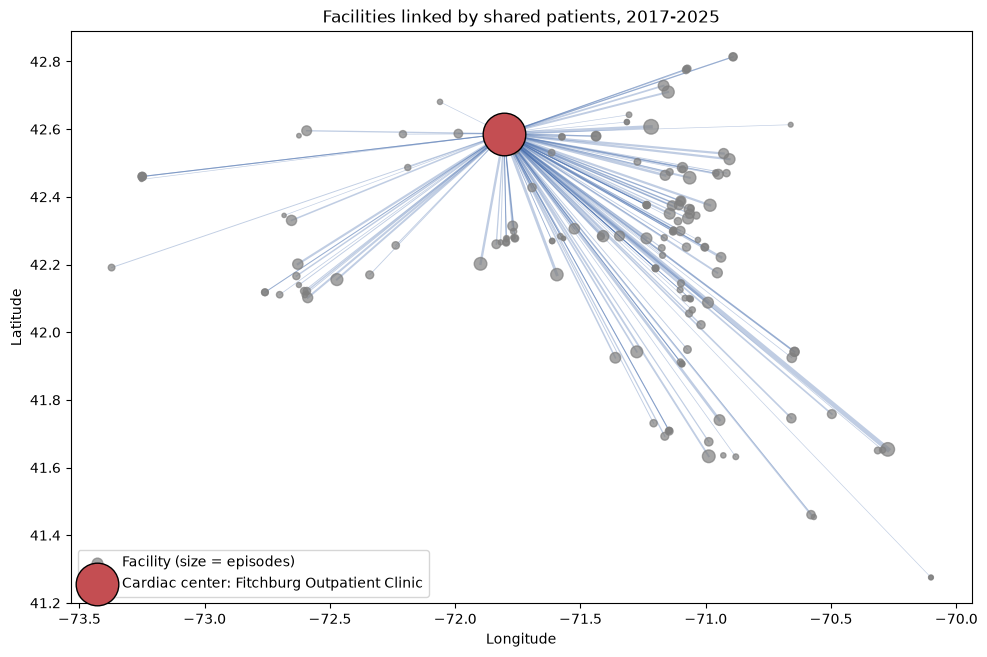

In [25]:
pos = {r.organization_id: (r.longitude, r.latitude) for r in nodes.itertuples()}
fig, ax = plt.subplots(figsize=(10, 8))
max_w = edges["shared_patients"].max()
for r in edges.itertuples():
    (x1, y1), (x2, y2) = pos[r.source], pos[r.target]
    ax.plot([x1, x2], [y1, y2], color="#4C72B0", alpha=0.35, lw=0.4 + 3 * r.shared_patients / max_w, zorder=1)
others = nodes[nodes["organization_id"] != HUB]
ax.scatter(others["longitude"], others["latitude"], s=8 + others["episodes_in_window"] / 8,
           color="grey", alpha=0.7, zorder=2, label="Facility (size = episodes)")
hub = nodes[nodes["organization_id"] == HUB]
ax.scatter(hub["longitude"], hub["latitude"], s=60 + hub["episodes_in_window"] / 8, color="#C44E52",
           edgecolor="black", zorder=3, label=f"Cardiac center: {HUB_NAME}")
ax.set_title("Facilities linked by shared patients, 2017-2025")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(loc="lower left")
ax.set_aspect(1 / np.cos(np.deg2rad(nodes["latitude"].mean())))
plt.tight_layout(); plt.show()

**Interpretation:** The map shows the star shape geographically. Lines radiate from the cardiac center in north-central Massachusetts to facilities across the state, from the western counties to Cape Cod, about 100 miles away. Patients travel long distances for cardiac care because it exists in only one place in this network. The thickest lines run to the larger general hospitals, which share the most patients with the hub and are therefore the most likely to absorb its patients if it closed.

## 4. The outage scenario: inputs
The cardiac center's share of the bed pool is its share of the average nightly census over 2017 to 2025, the same
basis used to size the 90 beds. Its episodes in 2023 to 2025 are the patients who would need to go elsewhere.

In [26]:
census_fac = q("""
    -- query: census_by_facility
    SELECT c.census_date, c.organization_id, c.patients_in_bed
    FROM mart.fact_daily_census c
    CROSS JOIN mart.analysis_window w
    WHERE c.census_date >= w.test_start_date
""")
network = q("""
    -- query: network_census
    SELECT census_date, patients_in_bed
    FROM mart.fact_daily_occupancy
    WHERE is_test_period = 1
    ORDER BY census_date
""")
hub_share_row = q(f"""
    -- query: hub_share
    SELECT SUM(CASE WHEN organization_id = '{HUB}' THEN patients_in_bed ELSE 0 END)::numeric
           / SUM(patients_in_bed) AS hub_share
    FROM mart.fact_daily_census
""")
hub_eps = q(f"""
    -- query: hub_episodes
    SELECT f.episode_id, f.patient_id, f.admit_date, f.los_days
    FROM mart.fact_episode f
    CROSS JOIN mart.analysis_window w
    WHERE f.organization_id = '{HUB}'
      AND f.admit_date + f.los_days - 1 >= w.test_start_date
""")
lung_eps = q("""
    -- query: lung_episodes
    SELECT e.admit_date, e.los_days
    FROM staging.episodes e
    CROSS JOIN mart.analysis_window w
    WHERE e.diagnosis_group = 'Lung cancer' AND e.is_planned_treatment
      AND e.admit_date + e.los_days - 1 >= w.test_start_date
      AND e.admit_date <= w.end_date
""")

DAYS = pd.date_range(TEST_START, TEST_END)
N_DAYS = len(DAYS)
BASE_CENSUS = network["patients_in_bed"].to_numpy(dtype=float)
assert len(BASE_CENSUS) == N_DAYS == 1096, "Census does not match the validated pipeline"
assert int((BASE_CENSUS / BEDS > MAX).sum()) == 7, "Days over 92% do not match the golden number"

HUB_SHARE = float(hub_share_row["hub_share"].iloc[0])
BEDS_LOST = int(round(HUB_SHARE * BEDS))
BEDS_LEFT = BEDS - BEDS_LOST


def nights_per_day(admit_dates, los, weights=None):
    """Bed nights per day of the test period for a set of stays (optionally weighted)."""
    los = np.asarray(los, dtype=int).clip(min=1)
    row = np.repeat(np.arange(len(los)), los)
    night_no = np.arange(los.sum()) - np.repeat(np.cumsum(los) - los, los)
    night = pd.to_datetime(pd.Series(admit_dates)).to_numpy()[row] + night_no.astype("timedelta64[D]")
    day = ((night - np.datetime64(TEST_START)) // np.timedelta64(1, "D")).astype(int)
    keep = (day >= 0) & (day < N_DAYS)
    w = np.ones(len(los)) if weights is None else np.asarray(weights, dtype=float)
    return np.bincount(day[keep], weights=w[row][keep], minlength=N_DAYS)


LUNG_NIGHTS = nights_per_day(lung_eps["admit_date"], lung_eps["los_days"])
hub_nights = nights_per_day(hub_eps["admit_date"], hub_eps["los_days"])
hub_census = (census_fac[census_fac["organization_id"] == HUB].set_index("census_date")["patients_in_bed"]
              .reindex(DAYS.date, fill_value=0).to_numpy(dtype=float))
assert np.allclose(hub_nights, hub_census), "Cardiac center nights do not match its census"

print(f"Cardiac center share of the nightly census, 2017-2025: {HUB_SHARE:.1%}")
print(f"Beds lost in an outage: {BEDS_LOST} of {BEDS}, leaving {BEDS_LEFT}")
print(f"Cardiac center episodes to move in 2023-2025: {len(hub_eps):,} "
      f"({hub_eps['patient_id'].nunique():,} patients), {hub_nights.sum():,.0f} bed nights")

Cardiac center share of the nightly census, 2017-2025: 11.9%
Beds lost in an outage: 11 of 90, leaving 79
Cardiac center episodes to move in 2023-2025: 2,596 (2,129 patients), 9,350 bed nights


**Interpretation:** The cardiac center holds **11.9% of the network's nightly census**, so an outage removes **11 of the 90 beds**, leaving 79. In 2023 to 2025 it treated 2,596 episodes (2,129 patients), accounting for 9,350 bed nights that would need to be absorbed elsewhere. The checks confirm the inputs match the pipeline: the census still shows 7 days above 92%, and the cardiac center's rebuilt nightly patient count matches its census exactly.

## 5. Where do the cardiac center's patients go?
Each patient moves to the other facility they used most in 2017 to 2025. Patients who used no other facility are
spread across the cardiac center's links in proportion to the patients each link shares, which follows the
network's existing pattern of shared care.

In [27]:
others_used = patient_facility[patient_facility["organization_id"] != HUB]
first_choice = (others_used.sort_values(["patient_id", "episodes", "organization_id"], ascending=[True, False, True])
                           .drop_duplicates("patient_id").set_index("patient_id")["organization_id"])

hub_edges = edges[(edges["source"] == HUB) | (edges["target"] == HUB)].copy()
hub_edges["neighbor"] = np.where(hub_edges["source"] == HUB, hub_edges["target"], hub_edges["source"])
spread = (hub_edges.set_index("neighbor")["shared_patients"] / hub_edges["shared_patients"].sum())

hub_eps["destination"] = hub_eps["patient_id"].map(first_choice)
has_other = hub_eps["destination"].notna()
print(f"Episodes going to the patient's own other facility: {has_other.sum():,} ({has_other.mean():.1%})")
print(f"Episodes spread across the cardiac center's links:  {(~has_other).sum():,} ({(~has_other).mean():.1%})")

# Extra bed nights per receiving facility per day
added = {}
for dest, grp in hub_eps[has_other].groupby("destination"):
    added[dest] = nights_per_day(grp["admit_date"], grp["los_days"])
spread_nights = nights_per_day(hub_eps.loc[~has_other, "admit_date"], hub_eps.loc[~has_other, "los_days"])
for dest, share in spread.items():
    added[dest] = added.get(dest, np.zeros(N_DAYS)) + share * spread_nights
ADDED = pd.DataFrame(added, index=DAYS.date)
assert np.isclose(ADDED.to_numpy().sum(), hub_nights.sum()), "Rerouted nights must equal the cardiac center's nights"
print(f"Receiving facilities: {ADDED.shape[1]}")

Episodes going to the patient's own other facility: 475 (18.3%)
Episodes spread across the cardiac center's links:  2,121 (81.7%)
Receiving facilities: 138


**Interpretation:** Only 475 of the cardiac center's episodes (18.3%) belong to patients who had also used another facility, so most patients have no established alternative. The remaining 2,121 episodes (81.7%) are spread across the hub's existing links, which in practice means all 138 connected facilities receive some cardiac patients. That is realistic for a closure of the only specialist center: the cardiac workload would not move as a block to a single replacement, it would scatter across general hospitals that currently send patients to the hub.

## 6. What happens to bed occupancy?
The patients still need a bed, so the network's nightly census stays the same, but the bed pool shrinks by the
cardiac center's share. Four cases are compared, with and without the recommended bed pathways (20% of planned
lung cancer stays as day cases).

In [28]:
PATHWAY_SHARE = 0.20


def occupancy(census, beds):
    occ = census / beds
    return {"beds": beds, "avg_occupancy_pct": 100 * occ.mean(), "peak_occupancy_pct": 100 * occ.max(),
            "days_over_85": int((occ > SAFE).sum()), "days_over_92": int((occ > MAX).sum()),
            "days_over_100": int((occ > 1).sum()), "goal_2_met": int((occ > MAX).sum()) == 0}


with_pathways = BASE_CENSUS - PATHWAY_SHARE * LUNG_NIGHTS
outage = pd.DataFrame([
    {"case": "1. Normal operation", **occupancy(BASE_CENSUS, BEDS)},
    {"case": "2. Normal operation + bed pathways", **occupancy(with_pathways, BEDS)},
    {"case": "3. Cardiac center outage", **occupancy(BASE_CENSUS, BEDS_LEFT)},
    {"case": "4. Cardiac center outage + bed pathways", **occupancy(with_pathways, BEDS_LEFT)},
]).set_index("case")

# How large a day-case share would the outage need to meet goal 2 again?
needed_share = next((s for s in np.round(np.arange(0, 1.0001, 0.05), 2)
                     if ((BASE_CENSUS - s * LUNG_NIGHTS) / BEDS_LEFT > MAX).sum() == 0), None)
print("Lung cancer day-case share needed to meet goal 2 during an outage: "
      + ("not reachable" if needed_share is None else f"{needed_share:.0%}"))
outage.round(1)

Lung cancer day-case share needed to meet goal 2 during an outage: 55%


,beds,avg_occupancy_pct,peak_occupancy_pct,days_over_85,days_over_92,days_over_100,goal_2_met
case,,,,,,,
1. Normal operation,90,70.8,96.7,49,7,0,False
2. Normal operation + bed pathways,90,66.0,90.4,7,0,0,True
3. Cardiac center outage,79,80.7,110.1,348,138,18,False
4. Cardiac center outage + bed pathways,79,75.2,103.0,159,35,2,False


**Interpretation:** An outage would be severe. With 79 beds instead of 90 and the same patients still needing care, average occupancy rises from 70.8% to 80.7%, days above the 92% maximum rise from **7 to 138**, days above the 85% safe level from 49 to 348 (almost a third of the period), and on **18 days** the network would need more beds than it has (peak 110%). The recommended bed pathways (20% of lung cancer stays as day cases) are enough for normal operation, removing every day above 92%, but not for an outage: they cut the days above 92% from 138 to 35 and leave 2 days above 100%. To meet goal 2 during an outage, the day-case share would need to reach **55%**, still within the evidence (up to 80%). The bed pathways are therefore also the hospital's main **resilience lever**: pushing them further than normal operation requires builds the spare capacity an outage would consume.

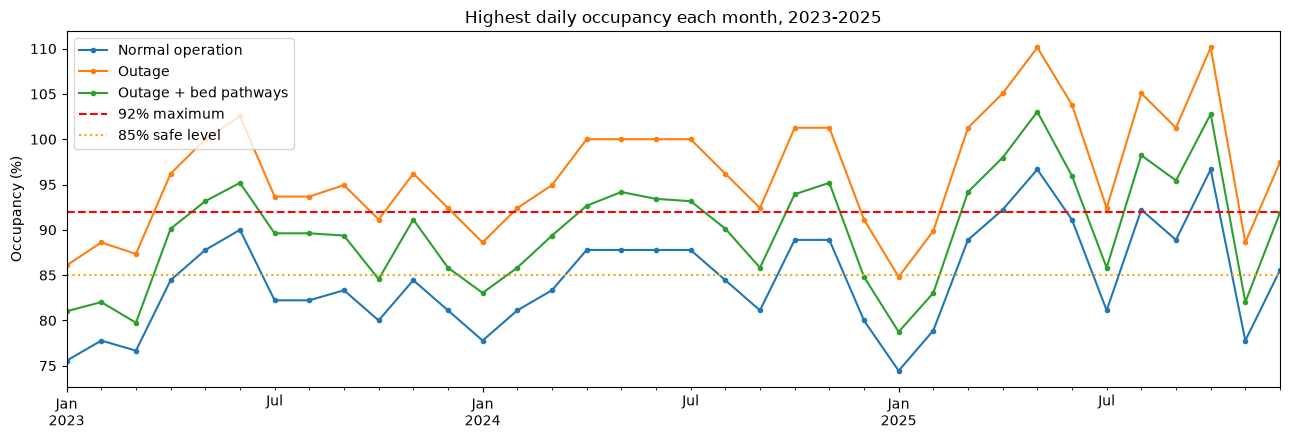

In [29]:
fig, ax = plt.subplots(figsize=(13, 4.5))
monthly = pd.DataFrame({"Normal operation": 100 * BASE_CENSUS / BEDS,
                        "Outage": 100 * BASE_CENSUS / BEDS_LEFT,
                        "Outage + bed pathways": 100 * with_pathways / BEDS_LEFT}, index=DAYS)
monthly.resample("MS").max().plot(ax=ax, marker=".")
ax.axhline(100 * MAX, color="red", ls="--", label="92% maximum")
ax.axhline(100 * SAFE, color="orange", ls=":", label="85% safe level")
ax.set_title("Highest daily occupancy each month, 2023-2025")
ax.set_ylabel("Occupancy (%)"); ax.set_xlabel("")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation:** The monthly chart shows how an outage turns busy periods into crises. Under normal operation the highest day of each month stays below 92% except in a few months of 2025. During an outage most months go above 92% and several above 100%, with the worst in spring and autumn 2025 (about 110%). The bed pathways (green) pull the outage line down by about 7 percentage points, enough to keep the quieter months under the maximum, but not the busiest ones. Because 2025 was already the busiest year, the hospital's exposure to an outage is growing.

## 7. The load on the receiving facilities
For each facility that absorbs cardiac center patients: its usual patients per night in 2023 to 2025, the extra
patients per night from the outage, and how much its load would grow.

In [30]:
usual = (census_fac.groupby("organization_id")["patients_in_bed"].sum() / N_DAYS)
load = pd.DataFrame({
    "usual_patients_per_night": usual.reindex(ADDED.columns).fillna(0),
    "extra_patients_per_night": ADDED.mean(),
    "peak_extra_patients": ADDED.max(),
    "extra_bed_nights": ADDED.sum(),
})
load["load_increase_pct"] = 100 * load["extra_patients_per_night"] / load["usual_patients_per_night"].replace(0, np.nan)
load = load.merge(nodes.set_index("organization_id")[["hospital_name", "city"]], left_index=True, right_index=True)
load = load.sort_values("extra_patients_per_night", ascending=False)

top = load.head(10)
print(f"Top 10 receiving facilities absorb {top['extra_bed_nights'].sum() / load['extra_bed_nights'].sum():.0%} "
      f"of the cardiac center's bed nights")
top[["hospital_name", "city", "usual_patients_per_night", "extra_patients_per_night",
     "peak_extra_patients", "load_increase_pct"]].round(2)

Top 10 receiving facilities absorb 26% of the cardiac center's bed nights


,hospital_name,city,usual_patients_per_night,extra_patients_per_night,peak_extra_patients,load_increase_pct
497f39dd-280e-3d58-af5b-c5e3a3a09b10,Cape Cod Hospital Inc,Hyannis,1.38,0.38,2.42,27.69
2836d9ac-c6a6-39d1-8f13-fdf0fc8928f4,Tewksbury Hospital,Tewksbury,1.64,0.28,1.37,17.07
05fcf001-ab24-3d7d-85f7-f64942d82738,Encompass Health Braintree Hospital Of Braintree,Framingham,0.78,0.26,1.42,33.03
845fbd9b-2d1c-39a8-8261-28ae40e4fab2,Milford Regional Medical Center,Upton,0.84,0.22,1.39,26.31
dd280187-8662-3732-af81-595d10572911,4499 Acushnet Avenue Operating Company LLC,New Bedford,0.55,0.20,1.36,36.81
eee00932-ca82-36bc-b7e8-e3fff6dbaeaa,Dana Farber Cancer Institute,Weymouth,0.53,0.19,2.02,36.81
217cb6f6-e822-3831-9d9d-ffa104971042,Encompass Health Rehabilitation Hosp Of New En...,Woburn,0.76,0.17,1.18,23.12
a2a41caf-758f-3962-8e5f-e6e603f93d17,Vibra Hospital Of Western Massachusetts LLC,Rochdale,1.14,0.16,2.10,13.84
af8566eb-8918-3ec7-ba44-92b6a2cf8097,North Shore Medical Center Inc,Salem,1.01,0.15,1.22,15.27
c7542447-e06e-32cb-b6db-243c23a0dbc2,Franciscan Hospital For Children Inc,Boston,0.74,0.15,1.22,20.74


**Interpretation:** At the level of individual facilities the extra load looks small in absolute terms: the busiest receiving facility, Cape Cod Hospital, would take on average 0.38 extra patients a night, with a peak of about 2.4. Relative to their usual inpatient load, though, the increases are large: 14% to 37% for the top 10 receivers, which together absorb 26% of the cardiac center's bed nights. The load is spread thinly across 138 facilities, which would reduce the strain on any one site but means **cardiac patients would be treated at general hospitals without the cardiac center's specialist teams**. Facility-level bed counts are not available in this data, so the strain on individual sites is shown as extra patients rather than occupancy.

## 8. Save the results
The network, its measures, the outage results and the receiving-facility load go to the mart for dashboard page 4.

In [31]:
net_nodes = centrality.merge(nodes[["organization_id", "city", "latitude", "longitude"]], on="organization_id")
coords = nodes.set_index("organization_id")[["latitude", "longitude"]]
net_edges = edges.copy()
net_edges[["source_lat", "source_lon"]] = coords.loc[net_edges["source"]].to_numpy()
net_edges[["target_lat", "target_lon"]] = coords.loc[net_edges["target"]].to_numpy()
net_outage = outage.reset_index()
net_outage["beds_lost"] = BEDS - net_outage["beds"]
net_load = load.reset_index().rename(columns={"index": "organization_id"})

with engine.begin() as conn:
    net_nodes.to_sql("net_nodes", conn, schema="mart", if_exists="replace", index=False)
    net_edges.to_sql("net_edges", conn, schema="mart", if_exists="replace", index=False)
    net_outage.to_sql("net_outage", conn, schema="mart", if_exists="replace", index=False)
    net_load.to_sql("net_receiving_load", conn, schema="mart", if_exists="replace", index=False)

q("""
    SELECT 'net_nodes' AS table_name, COUNT(*) AS rows FROM mart.net_nodes
    UNION ALL SELECT 'net_edges', COUNT(*) FROM mart.net_edges
    UNION ALL SELECT 'net_outage', COUNT(*) FROM mart.net_outage
    UNION ALL SELECT 'net_receiving_load', COUNT(*) FROM mart.net_receiving_load
""")

,table_name,rows
0,net_nodes,153
1,net_edges,138
2,net_outage,4
3,net_receiving_load,138


## 9. Summary
**Question:** how are the network's facilities connected, and what happens to bed capacity and to the other facilities if the most connected one goes down?

**The network is a star with a single point of failure.** All 138 links between facilities run through one cardiac center, Fitchburg Outpatient Clinic. It is the only cut point: without it, no two facilities in the network share patients. Every cardiac patient in the network is treated there.

**What a cardiac center outage would mean (2023 to 2025)**

| Case | Beds | Average occupancy | Days above 85% | Days above 92% | Days above 100% | Goal 2 |
|---|---|---|---|---|---|---|
| Normal operation | 90 | 70.8% | 49 | 7 | 0 | Not met |
| Normal operation + bed pathways (20% day cases) | 90 | 66.0% | 7 | 0 | 0 | **Met** |
| Cardiac center outage | 79 | 80.7% | 348 | 138 | 18 | Not met |
| Cardiac center outage + bed pathways (20% day cases) | 79 | 75.2% | 159 | 35 | 2 | Not met |

* **Capacity:** losing the cardiac center's 11 beds would push the network above the 92% maximum on 138 days and beyond its total capacity on 18.
* **Where patients go:** 82% of its patients have no other facility, so its workload would scatter across all 138 connected facilities, adding 14% to 37% to the usual load of the busiest receivers, and cardiac patients would be treated without specialist teams.
* **The bed pathways are the resilience lever.** The 20% day-case share recommended for normal operation is not enough during an outage, but a **55%** share would keep the network within the 92% maximum, still within the published evidence (up to 80%).

**Recommendations**
* **Treat the cardiac center as a single point of failure in planning.** The targeted cardiac follow-up program draws all of its patients from the cardiac center, and the network has no second cardiac site to fall back on.
* **Push the bed pathways beyond the minimum, towards 40% to 55% day cases.** This clears the 85% safe level in normal operation and builds the spare capacity an outage would need.
* **Arrange a cardiac contingency,** such as a partner hospital able to take cardiac admissions, to reduce the network's exposure to its single point of failure.

**Limitations**
* The star shape comes from how Synthea assigns patients to facilities, so the results illustrate what a single point of failure means rather than forecasting a real system.
* Beds are modelled as one network pool; facility-level bed counts are not available, so receiving facilities' strain is shown as extra patients rather than occupancy.
* The outage is assumed to last the whole of 2023 to 2025; a shorter outage would have a proportionally smaller effect on the number of days above each line, but the same effect on the busiest days.